# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(https://zerrokid.streamlit.app/)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [ ]:
!pip install pandas matplotlib seaborn pathlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [11]:
# Your data checks here
print(f"Shape: {df.shape}")

Shape: (100000, 13)


In [12]:
# column types check
df.dtypes.to_frame("data_type")

,data_type
user_id,int64
movie_id,int64
rating,int64
timestamp,str
age,int64
gender,str
occupation,str
zip_code,str
title,str
year,float64


In [13]:
# missing values check
df.isna().sum().to_frame("missing")

,missing
user_id,0
movie_id,0
rating,0
timestamp,0
age,0
gender,0
occupation,0
zip_code,0
title,0
year,30


In [ ]:
# duplicate rows check
print(f"Duplicate Rows: {df.duplicated().sum()}")

Duplicate Rows: 0


In [ ]:
# range of numeric columns check
df_numeric = df.select_dtypes(include='number')
ranges = df_numeric.max() - df_numeric.min()
ranges.to_frame('range')

,range
user_id,942.0
movie_id,1681.0
rating,4.0
age,66.0
year,76.0
decade,70.0
rating_year,1.0


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: I will count the number of movies in each genre.
- Why: So I can have a mmore clear picture of the distribution of genres in the dataset.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I will calculate the average rating for each genre based on the ratings of the movies that belong to that genre. For genres with very little data, I will set a minimum of 10 ratings.
- Why: to ensure that the average ratings are reliable and not skewed by a small number of ratings.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I will analyze the ratings over time by looking at the average rating per year, and I will exclude movies that have no release year.
- Why: to avoid skewing the results with incomplete data.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: movie's rating will be the mean of all its ratings. I will consider movies with at least 50 ratings and in case of a tie, I will include all movies that meet the criteria.
- Why: to ensure that the best movies are based on a sufficient number of ratings and to provide a fair comparison among movies.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

<Axes: title={'center': 'Distribution of Movies by Genre'}, xlabel='Count', ylabel='Genre'>

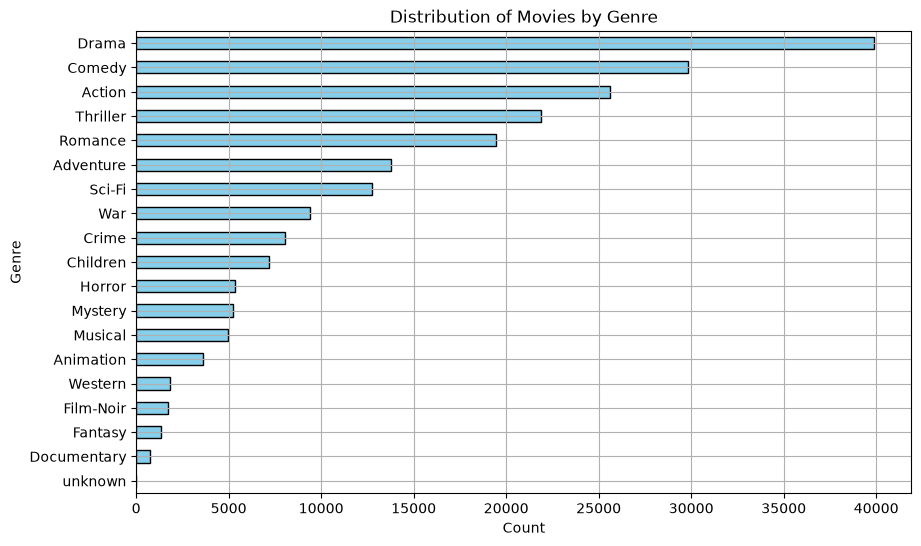

In [2]:
# Q1: your code here
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
count_by_genre_df = genre_df['genre'].value_counts().sort_values(ascending=True)
count_by_genre_df.plot(kind='barh', 
                       figsize=(10, 6), 
                       title='Distribution of Movies by Genre', 
                       xlabel='Count', 
                       ylabel='Genre',
                       color='skyblue',
                       edgecolor='black',
                       grid=True,)
# count_by_genre_df.to_frame('count')

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

Drama is the most common genre, with around 400000 movies, followed by Comedy with around 300000 movies. The least common genres are documentaries, fantasy, and Film-Noir, with less than 5000 movies each. I used the exploded dataframe to count the number of movies in each genre, which gives a clear picture of the distribution of genres in the dataset.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

<Axes: title={'center': 'Average Movie Ratings by Genre'}, xlabel='Average Rating', ylabel='Genre'>

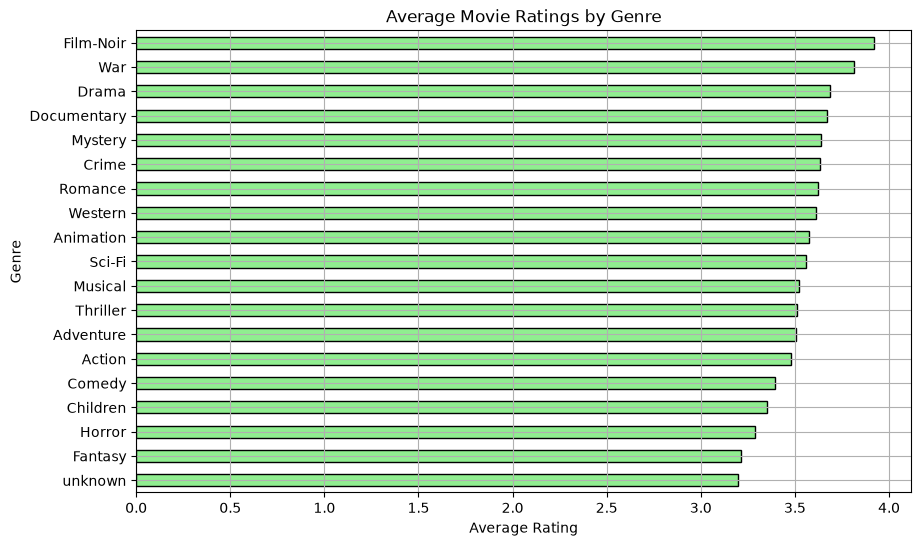

In [3]:
# Q2: your code here
average_rating_by_genre = genre_df.groupby('genre')['rating'].mean().sort_values(ascending=True)
average_rating_by_genre.plot(kind='barh',
                             figsize=(10, 6),
                             title='Average Movie Ratings by Genre',
                             xlabel='Average Rating',
                             ylabel='Genre',
                             color='lightgreen',
                             edgecolor='black',
                             grid=True)
# average_rating_by_genre.to_frame('average_rating').join(count_by_genre_df.to_frame('count')).sort_values(by='average_rating', ascending=False)

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

The highest average rating is for the genre "Film-Noir" with the average rating of 3.921523 with 1733 ratings. The lowest average rating is for the genre "unkown" with the average rating of 3.200000 with 10 ratings. The average ratings are based on the number of ratings for each genre, which provides a clear picture of the satisfaction level of each genre. Therefore, in order to ensure that the average ratings are reliable and not skewed by a small number of ratings, I set a minimum of 1000 ratings for each genre. Because of this, the most suitable genre for the lowest average rating is "Fantasy" with the average rating of 3.215237 with 1352 ratings.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

<Axes: title={'center': 'Average Movie Ratings by Year'}, xlabel='Year', ylabel='Average Rating'>

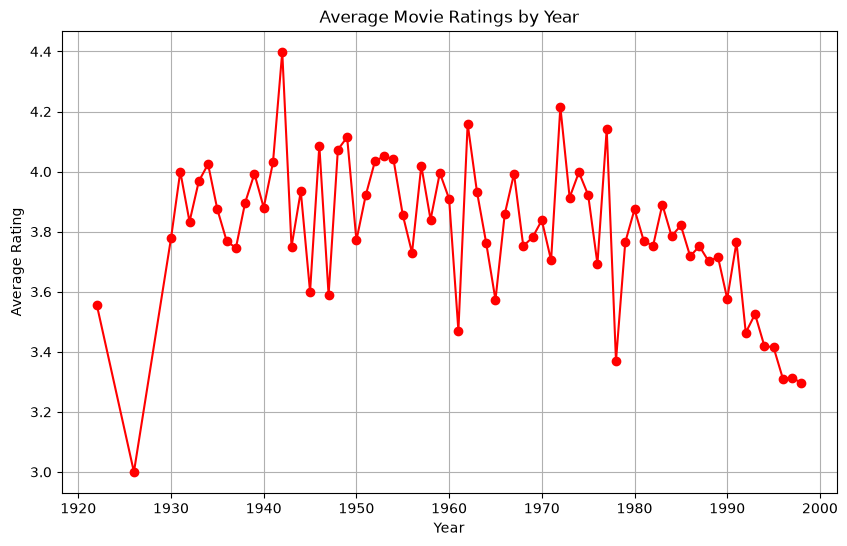

In [4]:
# Q3: your code here
yearly_avg_rating = df.groupby('year')['rating'].mean().sort_index()
yearly_avg_rating.plot(kind='line',
                       figsize=(10, 6),
                       title='Average Movie Ratings by Year',
                       xlabel='Year',
                       ylabel='Average Rating',
                       color='red',
                       marker='o',
                       grid=True)

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

the trend shows that the mean rating fluctuates over the years with a general decline from 1990 to 2000.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [5]:
# Q4: your code here
#What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?
movie_counts = df.groupby('title').size()
movies_with_50_ratings = movie_counts[movie_counts >= 50].index
best_rated_movies_50 = df[df['title'].isin(movies_with_50_ratings)].groupby('title')['rating'].mean().sort_values(ascending=False).head(5)
best_rated_movies_50.to_frame('average_rating')

,average_rating
title,
"Close Shave, A (1995)",4.491071
Schindler's List (1993),4.466443
"Wrong Trousers, The (1993)",4.466102
Casablanca (1942),4.456790
Wallace & Gromit: The Best of Aardman Animation (1996),4.447761


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_


> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: 
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: 
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week